# Session 3 — Multi-agent workflows with LangGraph

In Session 2a we built a team on the n8n canvas: a Literature Scout, a Data Analyst, and a human reviewer. In Session 2b we built *single* agents in Python. Here we put the two together: **a team of agents, each with its own tools, wired together as a LangGraph graph**. We use the same heart failure data and the same question as before:

> **Which risk factors at admission predict in-hospital heart failure after a myocardial infarction, what does the published literature say about them, and how well can our data predict it?**

| | Session 2a (n8n) | Session 2b (Python) | **This session** |
|---|---|---|---|
| Agents | Scout, Analyst | One agent per run | **Scout, Analyst, Reviewer** |
| Wiring | Drag and drop | The pattern is the graph | **We write the graph: state, nodes, edges** |
| PubMed tools | Built by hand, or the MCP node | none | **The same PubMed MCP server, connected from Python** |
| Review | A human clicks Approve | A critic with a rubric | **A Reviewer agent that re-runs the model with a tool** |

**By the end you should be able to:**
- Explain what a LangGraph *state*, *node*, and *edge* are.
- Connect an MCP server to a LangChain agent.
- Build a linear multi-agent workflow, then add a **conditional edge** so the Reviewer can send the work back.
- Compare the two workflows on cost and on what they produce.
---

## Setup - Before running the notebook

Use the same `.env` file and the same steps as Session 2b (provider, key, `pip install -r requirements.txt`). This session needs one extra package, `langchain-mcp-adapters`, which is already in `requirements.txt`. The Scout talks to a public PubMed server over the internet, so you need a connection unless you use `REPLAY = True`, which shows the runs saved in `materials/runs/` instead of calling the model or the server.

In [3]:
import warnings
warnings.filterwarnings("ignore")

import operator
from datetime import date
from typing import Annotated, Literal, TypedDict

from IPython.display import Markdown, display
from langchain.agents import create_agent
from langchain_mcp_adapters.client import MultiServerMCPClient
from langgraph.graph import END, START, StateGraph

from mi_tools import (MCP_URL, TOOLS, FinalModel, Literature, Review, arun_or_replay, check_answer, draw_graph, get_model,
                      list_variables, show_cost, show_final, show_trail, tools_by_agent, verify_answer)

REPLAY = False   # True = show the saved runs in materials/runs/ instead of calling the model and the PubMed server

llm = get_model()    # PROVIDER, MODEL, and the keys come from your .env file
if not REPLAY:
    print(f"{type(llm).__name__} ({getattr(llm, 'model', None) or llm.model_name}):", llm.invoke("Reply with the single word: ready").text)

ChatAnthropic (claude-sonnet-5-5): ready


---
## 1. LangGraph in five minutes

A LangGraph workflow has three parts:

| Part | What it is | In our team |
|---|---|---|
| **State** | A shared whiteboard: a dictionary every step can read and write | The question, the papers found, the analyst's answer, the review |
| **Node** | A Python function: it reads the state and returns the fields it wants to change | An agent, or a plain function |
| **Edge** | An arrow saying which node runs next | Scout → Analyst → Reviewer |

Here is a tiny graph with no model at all, so you can see the mechanics:

---
## 2. Meet the team

| Agent | Tools | What it does | Its output |
|---|---|---|---|
| **Literature Scout** | `pubmed_search_articles`, `pubmed_fetch_articles` (from an MCP server) | Finds papers on risk factors for heart failure after MI | `Literature`: up to 5 papers and the risk factors they name |
| **Data Analyst** | `list_variables`, `profile_data`, `compare_groups`, `train_model` (the Session 2b tools) | Builds the best model our data can support | `FinalModel`: the same answer format as Session 2b |
| **Reviewer** | `verify_answer`, `list_variables` | Re-runs the analyst's model and checks our rules, then checks the literature risk factors were considered | `Review`: *accept* or *revise*, with the issues |
| **Report** | none: a plain Python function | Fills a template with everything above | a Markdown report |

The last step is **not an agent**. Filling in a template needs no model, which is the same point as in Session 2a: use an agent only where you need one.

### Connecting an MCP server through LangChain
In Session 2a the n8n *MCP Client Tool* node connected to the PubMed MCP server. In Python the package `langchain-mcp-adapters` does the same job: it asks the server which tools it has and turns each one into an ordinary LangChain tool that `create_agent` can use. One thing differs: **MCP tools are asynchronous**, so we use `await` and `ainvoke`. Jupyter lets you write `await` directly in a cell.

In [4]:
if REPLAY:
    SCOUT_TOOLS = []
    print("REPLAY: not connecting to the PubMed server.")
else:
    client = MultiServerMCPClient({"pubmed": {"url": MCP_URL, "transport": "http"}})
    mcp_tools = await client.get_tools()
    print(f"{len(mcp_tools)} tools on the server: " + ", ".join(tool.name for tool in mcp_tools))
    SCOUT_TOOLS = [tool for tool in mcp_tools if tool.name in ("pubmed_search_articles", "pubmed_fetch_articles")]
    print("\nThe Scout gets only these:", [tool.name for tool in SCOUT_TOOLS])

12 tools on the server: pubmed_search_articles, pubmed_fetch_articles, pubmed_fetch_fulltext, pubmed_format_citations, pubmed_find_related, pubmed_spell_check, pubmed_lookup_mesh, pubmed_lookup_citation, pubmed_convert_ids, pubmed_fetch_citation_metrics, pubmed_europepmc_search, pubmed_europepmc_fetch

The Scout gets only these: ['pubmed_search_articles', 'pubmed_fetch_articles']


We give the Scout only the two tools it needs. An agent with fewer tools makes fewer mistakes and costs less. Call one tool by hand, as in Session 2b, to see what the agent will see:

In [5]:
if not REPLAY:
    search = next(tool for tool in SCOUT_TOOLS if tool.name == "pubmed_search_articles")
    reply = await search.ainvoke({"query": "Myocardial Infarction[MeSH] AND Heart Failure[MeSH]", "maxResults": 3})
    print(reply[0]["text"])       # an MCP tool returns a list of content blocks; the first one is text

## PubMed Search Results
**Query:** `Myocardial Infarction[MeSH] AND Heart Failure[MeSH]`
**Returned:** 3 of 12972 | **Offset:** 0
**Search URL:** <https://pubmed.ncbi.nlm.nih.gov/?term=Myocardial%20Infarction%5BMeSH%5D%20AND%20Heart%20Failure%5BMeSH%5D>

**PMIDs:** 39874177, 40521783, 40889512


> **Caution, as in Session 2a:** this server is run by an individual, not by NCBI. It can change or go down, your queries go to it, and the Scout only reports what the server returns. Keep `REPLAY = True` as your fallback.

### The question and the agents' instructions
Each agent gets short instructions that say *who it is* and *what to produce*. As in Session 2b, none of them say *how* to organize the work: that is for the agent, and for the graph.

In [6]:
QUESTION = ("Which risk factors at admission predict in-hospital heart failure after a myocardial infarction, what does the published "
            "literature say about them, and how well can our data predict it? Build the best model our data can support.")

TODAY = date.today().strftime("%Y/%m/%d")

SCOUT_PROMPT = f"""You are the Literature Scout on a research team studying heart failure after acute myocardial infarction (MI). Today's date is {TODAY}.
Find what published studies say about risk factors for heart failure after MI.
1. Turn the request into a short PubMed query without quotation marks, for example: Myocardial Infarction[MeSH] AND Heart Failure[MeSH]. Search with maxResults 10. Do not use dateRange unless the request names a time window; it then needs BOTH minDate and maxDate (YYYY/MM/DD).
2. Fetch the 5 most relevant PMIDs in one call (fewer only if fewer are relevant). If a search returns fewer than 5 results, fix or broaden the query and search again.
3. Report only what the fetched articles say. Never invent papers, PMIDs, or findings."""

ANALYST_PROMPT = """You are the Data Analyst on a research team studying heart failure after acute myocardial infarction (MI).
Our data: 1,700 patients admitted with acute MI to one hospital in Krasnoyarsk, Russia (1992-1995). The outcome is heart_failure, chronic heart failure during the hospital stay (394 patients, 23.2%).
Use your tools for every number. Never estimate or invent numbers. Report cross-validated results exactly as train_model reported them.
A literature scout has listed risk factors from published studies. Consider them, but use only variables known at admission, and say in your rationale which literature risk factors you used and which you left out and why."""

REVIEWER_PROMPT = """You are the Reviewer on a research team studying heart failure after acute MI. You check the Data Analyst's answer.
1. Call verify_answer with the analyst's predictors, model type, missing-data strategy, and reported AUC. Every line must PASS.
2. Check the literature: the Literature Scout listed risk factors from published studies. Use list_variables to see whether our data has a variable for each one. If it does, the analyst must have either used it as a predictor or explained in the rationale why it was left out. Anything neither used nor explained is an issue.
Answer 'revise' if any line FAILs or a literature risk factor is neither used nor explained; otherwise 'accept'. List at most 4 issues, one sentence each, with the specifics."""

scout = create_agent(llm, SCOUT_TOOLS, system_prompt=SCOUT_PROMPT, response_format=Literature)
analyst = create_agent(llm, TOOLS, system_prompt=ANALYST_PROMPT, response_format=FinalModel)
reviewer = create_agent(llm, [verify_answer, list_variables], system_prompt=REVIEWER_PROMPT, response_format=Review)

---
## 3. A linear workflow

The simplest graph is a straight line. Each agent does its job and hands its result to the next through the state:

```
 question ──► Scout ──► Analyst ──► Reviewer ──► Report
              PubMed    4 tools     2 tools      no model
```

First the state. Most fields are simply overwritten by the latest value. The ones marked `Annotated[list, operator.add]` **append** instead, so we keep every version.

In [7]:
class TeamState(TypedDict, total=False):
    question: str
    literature: Literature                               # written by the Scout
    answer: FinalModel                                   # written by the Analyst (the latest version)
    answers: Annotated[list, operator.add]               # every version of the analyst's answer
    review: Review                                       # written by the Reviewer (the latest)
    reviews: Annotated[list, operator.add]               # every review
    rounds: int                                          # how many reviews so far
    trace: Annotated[list, operator.add]                 # every agent message, so we can read the run afterwards
    report: str                                          # written by the Report node

Now the nodes. Each one is a function that reads the state, runs an agent, and returns only the fields it changes. They are `async` because the Scout's tools are. `config` carries the run's settings (and our cost counter) into each agent.

In [8]:
def literature_text(literature):
    papers = "\n".join(f"- PMID {p.pmid} ({p.year}): {p.finding}" for p in literature.papers)
    return f"{papers}\nRisk factors named: {', '.join(literature.risk_factors)}"

async def scout_node(state, config):
    result = await scout.ainvoke({"messages": [("user", state["question"])]}, config={**config, "recursion_limit": 30})
    return {"literature": result["structured_response"], "trace": result["messages"]}

async def analyst_node(state, config):
    task = f"{state['question']}\n\nWhat the Literature Scout found in PubMed:\n{literature_text(state['literature'])}"
    review = state.get("review")
    if review and review.verdict == "revise":            # a second round: show the analyst its last answer and the feedback
        task += (f"\n\nYour previous answer:\n{state['answer'].model_dump_json(indent=2)}\n\nThe Reviewer asked you to fix:\n"
                 + "\n".join(f"- {issue}" for issue in review.issues))
    result = await analyst.ainvoke({"messages": [("user", task)]}, config={**config, "recursion_limit": 50})
    answer = result["structured_response"]
    return {"answer": answer, "answers": [answer.model_dump()], "trace": result["messages"]}

async def reviewer_node(state, config):
    task = (f"The analyst's answer:\n{state['answer'].model_dump_json(indent=2)}\n\n"
            f"Risk factors named by the Literature Scout: {', '.join(state['literature'].risk_factors)}")
    result = await reviewer.ainvoke({"messages": [("user", task)]}, config={**config, "recursion_limit": 30})
    review = result["structured_response"]
    return {"review": review, "reviews": [review.model_dump()], "rounds": state.get("rounds", 0) + 1, "trace": result["messages"]}

def report_node(state):                                  # not an agent: no model, just a template
    answer, literature, review = state["answer"], state["literature"], state["review"]
    papers = "\n".join(f"- [PMID {p.pmid}](https://pubmed.ncbi.nlm.nih.gov/{p.pmid}/) ({p.year}): {p.finding}" for p in literature.papers)
    issues = "\n".join(f"- {issue}" for issue in review.issues) or "- none"
    drivers = "\n".join(f"- {driver}" for driver in answer.key_drivers)
    return {"report": f"""# Heart failure after MI: team report

## What the literature says
{papers}

Risk factors named: {', '.join(state['literature'].risk_factors)}

## Our model
- **Model:** {answer.model_type} (missing data: {answer.missing_strategy})
- **Predictors ({len(answer.predictors)}):** {', '.join(answer.predictors)}
- **Cross-validated AUC {answer.cv_auc:.3f}**, PR-AUC {answer.pr_auc:.3f}

**Key drivers**
{drivers}

**Rationale:** {answer.rationale}

## Review ({state['rounds']} round{'s' if state['rounds'] != 1 else ''}; last verdict: {review.verdict})
{issues}
"""}

Now wire the nodes together with edges and look at the graph we built (a solid arrow always runs; a dotted arrow, which you will see in the next section, is a *conditional* edge):

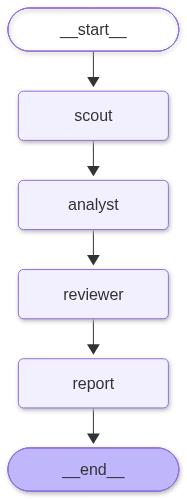

In [9]:
linear = StateGraph(TeamState)
linear.add_node("scout", scout_node)
linear.add_node("analyst", analyst_node)
linear.add_node("reviewer", reviewer_node)
linear.add_node("report", report_node)
linear.add_edge(START, "scout")
linear.add_edge("scout", "analyst")
linear.add_edge("analyst", "reviewer")
linear.add_edge("reviewer", "report")
linear.add_edge("report", END)
linear_app = linear.compile()

draw_graph(linear_app)

Run it. `run_team` starts the graph with just the question; everything else is written to the state by the agents. (`REPLAY = True` shows the saved run instead.)

In [10]:
def run_team(app):
    async def run(stats):
        state = await app.ainvoke({"question": QUESTION}, config={"callbacks": [stats], "recursion_limit": 60})
        extra = {"literature": state["literature"].model_dump(), "answers": state["answers"], "reviews": state["reviews"], "report": state["report"]}
        return state["trace"], state["answer"], extra
    return run

def show_team(name, final, summary, extra):
    print("SCOUT found:")
    for paper in extra["literature"]["papers"]:
        print(f"  PMID {paper['pmid']} ({paper['year']}): {paper['finding']}")
    print("  Risk factors named:", ", ".join(extra["literature"]["risk_factors"]))
    print("\nTOOLS EACH AGENT USED:")
    for agent, sequence in tools_by_agent(name).items():
        print(f"  {agent}: {sequence}")
    print()
    for i, (answer, review) in enumerate(zip(extra["answers"], extra["reviews"]), 1):
        print(f"ANALYST, version {i}: {answer['model_type']}, {len(answer['predictors'])} predictors, reported AUC {answer['cv_auc']:.3f}")
        print(f"REVIEWER: {review['verdict'].upper()}" + "".join(f"\n   - {issue}" for issue in review["issues"]))
    print()
    show_final(final)
    print()
    show_cost(summary)

linear_messages, linear_final, linear_summary, linear_extra = await arun_or_replay("linear", REPLAY, run_team(linear_app))
show_team("linear", linear_final, linear_summary, linear_extra)

SCOUT found:
  PMID 36638919 (2023): In 714 anterior STEMI patients treated with primary PCI, 54.2% had in-hospital HF, and independent predictors were ventricular fibrillation (OR 5.66), community-acquired pneumonia (OR 4.72), older age, lower LVEF and higher peak NT-proBNP.
  PMID 39587472 (2024): In 676 AMI patients after emergency PCI (13.46% in-hospital HF), age, troponin, D-dimer, LVEF and Gensini score were independent predictors, and the nomogram reached an AUC of 0.87 in training and 0.85 in validation.
  PMID 41486117 (2026): Across 14 retrospective models (AUC 0.847-0.966, all at high risk of bias), the meta-analysis found 19 significant predictors including Killip class, age, Gensini score, D-dimer, NT-proBNP, NLR, troponin, creatinine, hs-CRP, hypertension, diabetes, time from symptom onset to admission, number of diseased vessels and arrhythmia.
  PMID 40725875 (2025): Of 28 mostly retrospective Chinese studies (C-statistics 0.6-0.9), only 2 had external validation and ne

**What to look at.**
- **Scout:** did it fetch real papers (PMIDs you can look up)? Which risk factors did it name?
- **Hand-off:** do the Analyst's predictors and rationale mention what the Scout found?
- **Reviewer:** did it call `verify_answer`? What did it say about the literature risk factors?
- **In this workflow the review does not change anything.** Even if the Reviewer says *revise*, the graph goes straight to the report. The report shows the verdict, but nobody acts on it. That is what the next section fixes.

The report the last node wrote (no model involved):

In [11]:
display(Markdown(linear_extra["report"]))

# Heart failure after MI: team report

## What the literature says
- [PMID 36638919](https://pubmed.ncbi.nlm.nih.gov/36638919/) (2023): In 714 anterior STEMI patients treated with primary PCI, 54.2% had in-hospital HF, and independent predictors were ventricular fibrillation (OR 5.66), community-acquired pneumonia (OR 4.72), older age, lower LVEF and higher peak NT-proBNP.
- [PMID 39587472](https://pubmed.ncbi.nlm.nih.gov/39587472/) (2024): In 676 AMI patients after emergency PCI (13.46% in-hospital HF), age, troponin, D-dimer, LVEF and Gensini score were independent predictors, and the nomogram reached an AUC of 0.87 in training and 0.85 in validation.
- [PMID 41486117](https://pubmed.ncbi.nlm.nih.gov/41486117/) (2026): Across 14 retrospective models (AUC 0.847-0.966, all at high risk of bias), the meta-analysis found 19 significant predictors including Killip class, age, Gensini score, D-dimer, NT-proBNP, NLR, troponin, creatinine, hs-CRP, hypertension, diabetes, time from symptom onset to admission, number of diseased vessels and arrhythmia.
- [PMID 40725875](https://pubmed.ncbi.nlm.nih.gov/40725875/) (2025): Of 28 mostly retrospective Chinese studies (C-statistics 0.6-0.9), only 2 had external validation and nearly all were at high risk of bias; the most common predictors were age, Gensini score, hs-CRP, multivessel disease, LVEF and GRACE score.
- [PMID 37716540](https://pubmed.ncbi.nlm.nih.gov/37716540/) (2024): In 3174 STEMI patients in a registry, 22.3% had HF at admission (Killip ≥2). These patients were older, more often female, hypertensive and diabetic and received less reperfusion, and HF at admission independently predicted in-hospital death (OR 4.88).

Risk factors named: older age, female sex, hypertension, diabetes, high Killip class at admission, lower LVEF, higher NT-proBNP, higher troponin, higher D-dimer, higher hs-CRP, higher neutrophil-to-lymphocyte ratio, higher neutrophil-to-HDL cholesterol ratio, higher modified shock index, higher serum creatinine, ventricular fibrillation or arrhythmia, community-acquired pneumonia, higher Gensini score, multivessel coronary disease, longer time from symptom onset to admission, higher GRACE score, anterior wall infarction, lack of reperfusion

## Our model
- **Model:** logistic (missing data: impute)
- **Predictors (15):** age, sex, diabetes, prior_heart_failure, anterior_mi, lateral_mi, inferior_mi, atrial_fibrillation_at_admission, ecg_rhythm_atrial_fibrillation, chronic_bronchitis, serum_sodium, white_blood_cell_count, hypertension_stage, time_to_hospital, cardiogenic_shock_at_admission
- **Cross-validated AUC 0.742**, PR-AUC 0.552

**Key drivers**
- prior_heart_failure (stage I in the history; adjusted OR 30.14, 95% CI 16.38-55.48)
- chronic_bronchitis (OR 2.56)
- diabetes (OR 2.00)
- age (OR 1.03 per year)
- lateral_mi (OR 1.36 per ECG-severity step)
- ecg_rhythm_atrial_fibrillation (OR 2.14, p=0.085, not significant)

**Rationale:** I used a 15-variable logistic model with median imputation. It has 394 events, about 21.9 events per model column. Cross-validated results: AUC 0.742 ± 0.033, PR-AUC 0.552 ± 0.037 (no-skill 0.232), Brier 0.144. Other models did not do better. A gradient-boosting model on the same 15 variables reached AUC 0.738 and PR-AUC 0.546. A 45-variable gradient-boosting model reached 0.728 and 0.547. A 45-variable L1-penalized logistic model reached 0.730 and 0.539. A complete-case logistic model on 13 variables reached 0.720 and 0.524 but dropped 276 patients. I therefore kept the simplest, most interpretable model. The 15 variables were chosen using what the broader models showed, and the same data were used to evaluate them. The 0.742 may therefore be slightly optimistic and has no external validation. Discrimination is modest, not high. Literature risk factors I used, all known at admission: older age, diabetes, hypertension (stage), anterior infarction (anterior_mi), arrhythmia (atrial fibrillation at admission and on the ECG), time from symptom onset to hospital (time_to_hospital), and female sex (as the sex variable). I also used cardiogenic shock at admission, in place of Killip class, as the closest available severity marker. I tested ventricular fibrillation at admission in the first logistic model (OR 0.33, p=0.308, only a few events) but dropped it. In this data, age, diabetes and anterior MI were associated with HF in the expected direction. Sex, hypertension stage and time to hospital had no clear independent effect. The cardiogenic shock OR was below 1 (0.07). That is probably because there are very few shock cases, and I would not interpret it causally. Pulmonary edema at admission was tested in the first logistic model (OR 0.88, p=0.679) and left out of the final model. It overlaps conceptually with the outcome (HF at presentation), and it added no independent signal. Literature factors left out because the dataset has no such variable at admission: LVEF, NT-proBNP, troponin, D-dimer, hs-CRP, NLR and neutrophil-to-HDL ratio, modified shock index, creatinine, Gensini score, multivessel disease, GRACE score, community-acquired pneumonia and Killip class. LVEF, Gensini score and multivessel disease would also come from echo or angiography after admission. Reperfusion was only partly available, as fibrinolysis variables. I only ran those variables in the broad boosting and L1 models, not in the final one. Prior heart failure and chronic bronchitis were strong in this data but were not named by the scout. Prior heart failure was significant only for stage I (OR 30.14). Stages 3 and 4 had ORs of about 1.5 and were not significant. That odd pattern may be a coding or definition artifact in this 1992-1995 single-centre cohort, so it needs checking. These associations are not causal.

## Review (1 round; last verdict: revise)
- Lack of reperfusion is a literature risk factor and the data has fibrinolysis variables known at admission (fibrinolysis_streptase, fibrinolysis_celiasum_*, fibrinolysis_streptodecase_1_5m_iu), but the final model leaves them out; the rationale only says they were 'partly available' and were run in the broad models, so it gives no real reason for the exclusion. The analyst should either add a reperfusion indicator, such as any fibrinolysis, to the final model or explain why it was dropped.


The full trail of every model call and tool call, for every agent, is saved next to the run in `materials/runs/linear_trace.md`, and `show_trail("linear")` prints it here.

---
## 4. A non-linear workflow: the Reviewer can send the work back

A straight line cannot react to what happened. A **conditional edge** can: after the Reviewer, a small function looks at the state and *chooses* the next node.

```
 question ──► Scout ──► Analyst ──► Reviewer ──► verdict?
                          ▲                        │ accept  ─────────────► Report
                          └──── revise (max 2 rounds) ◄──┘
```

When the verdict is *revise*, the Analyst runs again. This time its task also contains its previous answer and the Reviewer's issues (see `analyst_node` above). We stop after 2 reviews, so the loop cannot run forever.

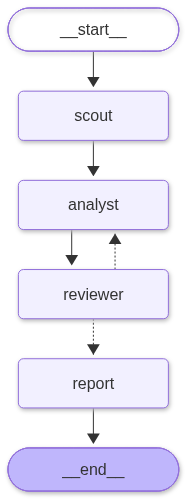

In [12]:
MAX_ROUNDS = 2

def after_review(state):
    """The router: where does the work go after the Reviewer?"""
    if state["review"].verdict == "revise" and state["rounds"] < MAX_ROUNDS:
        return "analyst"
    return "report"

loop = StateGraph(TeamState)
loop.add_node("scout", scout_node)
loop.add_node("analyst", analyst_node)
loop.add_node("reviewer", reviewer_node)
loop.add_node("report", report_node)
loop.add_edge(START, "scout")
loop.add_edge("scout", "analyst")
loop.add_edge("analyst", "reviewer")
loop.add_conditional_edges("reviewer", after_review, {"analyst": "analyst", "report": "report"})     # the only new line of wiring
loop.add_edge("report", END)
loop_app = loop.compile()

draw_graph(loop_app)

In [13]:
loop_messages, loop_final, loop_summary, loop_extra = await arun_or_replay("loop", REPLAY, run_team(loop_app))
show_team("loop", loop_final, loop_summary, loop_extra)

SCOUT found:
  PMID 39587472 (2024): In 676 AMI patients undergoing emergency PCI (13.46% in-hospital HF), age, troponin, D-dimer, LVEF and Gensini score were independent predictors, and a nomogram built on them had an AUC of 0.87 in training and 0.85 in validation.
  PMID 33319509 (2021): This review says HF is still a frequent complication of MI and that clinical risk factors plus biochemical, genetic and imaging biomarkers predict its development. The abstract does not list them, and it recommends a multimodality approach to spot at-risk patients early.
  PMID 41486117 (2026): Across 14 retrospective models (AUC 0.847-0.966), the meta-analysis found 19 significant predictors including Killip class, age, NT-proBNP, troponin, creatinine, hs-CRP, diabetes, hypertension, Gensini score, D-dimer and time to admission, but all studies had high risk of bias.
  PMID 37716540 (2024): In 3174 STEMI patients, 22.3% had HF at admission (Killip ≥2). These patients were older, more often female, h

**What to look at.**
- How many rounds did it take? If the Reviewer said *revise*, what exactly did it ask for, and did the Analyst's second version fix it?
- If the Reviewer accepted in round 1, the loop never ran and this workflow behaved like the linear one. **That is a legitimate outcome:** the loop is a safety net, not a guarantee. Re-run the cell (or look at the saved run) to see a case where it sends work back.
- Compare the second version's AUC and predictors with the first. A revision should make the answer more defensible, not necessarily better-scoring. In the saved run, for example, the Reviewer noticed that *less reperfusion* is a literature risk factor and that our data has fibrinolysis variables the Analyst had not explained. The Analyst answered with a justified rationale and kept the same model.

In [14]:
display(Markdown(loop_extra["report"]))

# Heart failure after MI: team report

## What the literature says
- [PMID 39587472](https://pubmed.ncbi.nlm.nih.gov/39587472/) (2024): In 676 AMI patients undergoing emergency PCI (13.46% in-hospital HF), age, troponin, D-dimer, LVEF and Gensini score were independent predictors, and a nomogram built on them had an AUC of 0.87 in training and 0.85 in validation.
- [PMID 33319509](https://pubmed.ncbi.nlm.nih.gov/33319509/) (2021): This review says HF is still a frequent complication of MI and that clinical risk factors plus biochemical, genetic and imaging biomarkers predict its development. The abstract does not list them, and it recommends a multimodality approach to spot at-risk patients early.
- [PMID 41486117](https://pubmed.ncbi.nlm.nih.gov/41486117/) (2026): Across 14 retrospective models (AUC 0.847-0.966), the meta-analysis found 19 significant predictors including Killip class, age, NT-proBNP, troponin, creatinine, hs-CRP, diabetes, hypertension, Gensini score, D-dimer and time to admission, but all studies had high risk of bias.
- [PMID 37716540](https://pubmed.ncbi.nlm.nih.gov/37716540/) (2024): In 3174 STEMI patients, 22.3% had HF at admission (Killip ≥2). These patients were older, more often female, hypertensive and diabetic, received less reperfusion, and had higher in-hospital mortality (28.4% vs 3.0%).
- [PMID 38685603](https://pubmed.ncbi.nlm.nih.gov/38685603/) (2024): In the JAMIR registry, 3.8% of AMI survivors were later admitted for HF. Independent risk factors were older age, female sex, Killip class ≥2 at admission, LVEF <40%, eGFR ≤30, history of malignancy and no ACE inhibitor at discharge.

Risk factors named: older age, female sex, Killip class ≥2 at admission, reduced LVEF (<40%), elevated troponin, elevated NT-proBNP, elevated D-dimer, higher Gensini score / more diseased coronary vessels, renal dysfunction (elevated creatinine, low eGFR), diabetes, hypertension, elevated hs-CRP / inflammatory markers (NLR, NHR), modified shock index, arrhythmia, longer time from symptom onset to admission, history of malignancy, less reperfusion

## Our model
- **Model:** gradient_boosting (missing data: native)
- **Predictors (13):** age, sex, prior_heart_failure, hypertension_stage, diabetes, cardiogenic_shock_at_admission, atrial_fibrillation_at_admission, anterior_mi, lateral_mi, inferior_mi, serum_sodium, angina_functional_class, prior_mi_count
- **Cross-validated AUC 0.732**, PR-AUC 0.525

**Key drivers**
- prior_heart_failure (stage I)
- age
- lateral_mi
- diabetes
- anterior_mi
- atrial_fibrillation_at_admission
- cardiogenic_shock_at_admission

**Rationale:** Model: gradient boosting with native missing-value handling. It uses 13 admission-only predictors (16 model columns) on all 1,700 patients (394 events, 24.6 events per column). 5-fold CV AUC is 0.732 ± 0.026, PR-AUC 0.525 (no-skill baseline 0.232), Brier 0.147. Discrimination is modest.

Revision after review: I tested the inflammatory and shock-index proxies the Reviewer pointed out. I was wrong earlier to say no such variables exist.
- Inflammatory markers (hs-CRP, NLR and NHR are not in the data). White blood cell count (7.4% missing) and ESR (11.9% missing) are the nearest admission variables. Mean WBC was 8.75 with HF vs 8.79 without (p=0.859). Mean ESR was 14.29 vs 13.19 (p=0.106). Neither is a significant univariate predictor.
- Modified shock index (not computable, because there is no admission heart rate value or MAP-based index). Nearest proxies are ICU systolic and diastolic BP (15.7% missing) and the ECG sinus tachycardia flag (heart rate >90; 8.9% missing). Mean systolic BP was 138.3 with HF vs 133.6 without (p=0.018). Mean diastolic BP was 84.6 vs 82.2 (p=0.033). So HF patients had slightly higher BP, the opposite of the low-BP, high-shock-index pattern in the literature. Sinus tachycardia was present in 25.5% of HF patients vs 22.7% of those without (p=0.271), which is not significant.
- Adding these variables to the model did not help (gradient boosting, native missing handling, 5-fold CV):
  - Compact model plus WBC and ESR: AUC 0.725, PR-AUC 0.522.
  - Compact model plus ICU BPs and sinus tachycardia: AUC 0.715, PR-AUC 0.509.
  - Compact model plus all five: AUC 0.717, PR-AUC 0.514.
  - Compact model alone: AUC 0.732, PR-AUC 0.525.
  These variables ranked near zero in importance. I therefore left them out of the final model for parsimony, because they added nothing and slightly lowered CV performance. The differences are within the fold standard deviations.

Other models I tried earlier performed about the same. A 30-variable boosting model had AUC 0.726 and PR-AUC 0.542. A penalized logistic model with 17 variables had AUC 0.723 and PR-AUC 0.522. A complete-case logistic model had AUC 0.724 and PR-AUC 0.534. I chose the compact boosting model for its best AUC, use of all patients, and adequate events per column.

Literature risk factors I used (available at admission in our data):
- Older age: mean 64.9 in patients with HF vs 61.0 in those without. It is the second strongest driver.
- Female sex: HF in 28.5% of women vs 20.0% of men. It adds little after adjustment (OR 0.94).
- Diabetes: adjusted OR 1.61.
- Hypertension: included as hypertension_stage, not significant after adjustment (OR 0.99).
- Arrhythmia: atrial fibrillation at admission, adjusted OR 2.14.
- Acute severity: cardiogenic shock at admission is the closest proxy for Killip class. It is rare (46 patients, only 1 with chronic HF, probably because of early death as a competing outcome). Pulmonary edema was not associated (p=0.734) and was left out.
- Infarct extent: ECG anterior, lateral and inferior MI scores are proxies for the Gensini score and infarct size. Lateral MI had OR 1.32.
- Time from symptom onset to admission: not significant (p=0.171), 7.4% missing, left out of the final model.
- Inflammatory markers and shock index: only the proxies above were available, and they were tested and not retained.

Literature risk factors I left out because they are not in the dataset or are not available at admission: Killip class, LVEF, troponin, NT-proBNP, D-dimer, Gensini score, creatinine/eGFR, hs-CRP/NLR/NHR, a true modified shock index, and history of malignancy. Reperfusion is recorded only as fibrinolytic drug use, a treatment variable that added nothing in the larger models. I used no discharge medications such as ACE inhibitors and no information from after admission.

What the data add: the strongest predictor was a history of stage I chronic heart failure (HF in 87.4% vs 18.7% with no prior HF; adjusted OR 26.3). The outcome therefore partly reflects pre-existing HF rather than purely new incident HF.

Caveats: the data come from a single centre in 1992–1995, before modern reperfusion and biomarkers. An AUC of 0.73 is well below the 0.85 or higher reported by studies that used troponin, LVEF and angiography. The model should not be used as a clinical tool.

## Review (2 rounds; last verdict: accept)
- none


---
## 5. Compare the two workflows

Same agents, same tools, same question. Only the wiring differs.

In [15]:
import pandas as pd

runs = {"Linear": (linear_final, linear_summary, linear_extra), "With review loop": (loop_final, loop_summary, loop_extra)}
rows = []
for name, (final, summary, extra) in runs.items():
    rows.append({"workflow": name, **{key: summary.get(key) for key in ("llm_calls", "tool_calls", "tokens", "cost_usd", "seconds")},
                 "reviews": len(extra["reviews"]), "last verdict": extra["reviews"][-1]["verdict"], "model": final.model_type,
                 "predictors": len(final.predictors), "reported AUC": final.cv_auc, **check_answer(final)})
table = pd.DataFrame(rows).set_index("workflow").drop(columns="valid", errors="ignore")
table.replace({True: "✅", False: "❌"})

,llm_calls,tool_calls,tokens,cost_usd,seconds,reviews,last verdict,model,predictors,reported AUC,verified_auc,reported_auc_matches,admission_only,no_variable_over_30pct_missing,events_per_column_at_least_10
workflow,,,,,,,,,,,,,,,
Linear,10,12,100509,0.251762,63,1,revise,logistic,15,0.742,0.742,✅,✅,✅,✅
With review loop,17,29,167386,0.412812,109,2,accept,gradient_boosting,13,0.732,0.732,✅,✅,✅,✅


Bad pipe message: %s [b'am\r\ntraceparent: 00-4304213e0b9027330ce7a4e073a5f08a-2f237fc12dba4d5f-00\r\nContent-Type: application/json\r\nContent', b'ength: 212\r\n\r\n{"jsonrpc":"2.0","id":1,"metho']
Bad pipe message: %s [b':"initialize","params":{"protocolVersion":"2025-06-18","capabilities":{"tools":{},"resources":{},"p']
Bad pipe message: %s [b'am\r\ntraceparent: 00-e3e1d2b2b89297fe80d7e1518f8b7257-dddacd69e70496a3-00\r\nContent-Type: application/json\r\nContent', b'ength: 212\r\n\r\n{"jsonrpc":"2.0","id":1,"metho']
Bad pipe message: %s [b':"initialize","params":{"protocolVersion":"2025-06-18","capabilities":{"tools":{},"resources":{},"p']


---
## Discussion

**When is a graph better than one agent?**
- When the work has **distinct roles with different tools** (the Scout needs PubMed, the Analyst needs data tools, the Reviewer needs a checker). Each agent sees only what it needs.
- When you want a **check that can say no**. The loop is the same idea as Reflection in Session 2b, with a Reviewer that verifies by re-running the model rather than by opinion.
- When the **hand-offs should be visible**: each step writes to the state, so you can read exactly what passed from one agent to the next.

**Limits to be open about**
- **More agents, more cost.** Every agent is at least one more model call, and a revision round repeats the Analyst's work.
- **The Reviewer can be wrong,** or too lenient. `verify_answer` checks the numbers and our rules; whether a literature risk factor was "considered" is still the model's judgment.
- **The Scout is only as good as its search.** It reads what the MCP server returns, and PubMed's ranking decides which papers come back.
- **One run is an example, not a benchmark.** Agents choose their own tool calls, so a re-run can differ.

**Where to go next (not built here)**
- **Parallel branches:** the Scout and the Analyst do not need each other, so they could run at the same time and meet at the Reviewer.
- **A human in the loop:** pause the graph for a person to approve the Analyst's answer, as the *Human Review* step did in n8n (LangGraph calls this an *interrupt*).
- **More tools for the Analyst,** such as the ML-model tools from Session 2b.

---
## Troubleshooting

| Symptom | Likely cause and fix |
|---|---|
| `ModuleNotFoundError: langchain_mcp_adapters` | `pip install -r requirements.txt` (or `pip install langchain-mcp-adapters`), then restart the kernel |
| `pip` fails with `Failed building wheel for cryptography` | On an Intel Mac, `pip install "cryptography<49"` first, then install the requirements again |
| `NotImplementedError` from a tool, or "StructuredTool does not support sync invocation" | MCP tools are async: use `await ...ainvoke(...)` (or `await graph.ainvoke(...)`), not `invoke` |
| `await` is a SyntaxError | Run in Jupyter or VS Code notebooks, not in a plain `.py` script (there, wrap the code in `asyncio.run`) |
| The Scout connects but returns nothing, or errors | The public server may be down or slow. Set `REPLAY = True` |
| The Scout reports fewer than 5 papers | Its first query was too narrow or malformed. Check the Scout's tool calls with `show_trail("linear")` and re-run |
| The loop never runs | The Reviewer accepted in round 1. That is a valid result; re-run, or open the saved `loop` run |
| `tool_choice ... not supported` | `pip install -U langchain-anthropic anthropic` and restart the kernel (see Session 2b) |
| Old numbers after editing `mi_tools.py` | Restart the kernel: Python keeps the old module in memory |